# 08 · Ship it to whom? Targeting the Starter Bonus with a causal forest

**Question.** The test says the Starter Bonus works. It costs money, so should every new player get it, or only some? Which players, how much does targeting gain, and how sure can we be with the data one experiment gives us?

**Milestone.** M10 · **Theory notes:** [hte](../docs/theory/hte.md), [causal-forests](../docs/theory/causal-forests.md), [policy-learning](../docs/theory/policy-learning.md), [metalearners](../docs/theory/metalearners.md)

## Where we are

Notebook 06 showed that at the Small preset (+2 points on average) the bonus earns only about 0.7¢ per player once its cost is paid, and that 30,000 players cannot even show it pays. But the lift is not the same for everyone: the simulator gives tier 3 countries 1.5× the average lift and paid social 1.25× (DECISIONS.md), and the cost is not the same either. This notebook does what the brief asks for after the ship decision: **policy learning, done once on the final sample**, with the safeguards of brief §8 (covariates fixed in advance, honest sample splitting, an overall test before any segment is shown, and a plain subgroup comparison the forest has to beat). On simulated data the truth is known, so every rule is scored against it.

## 1. Model

### Who is worth a bonus

For a player with sign-up attributes $x$, the conditional average treatment effect (CATE) is

$$
\tau(x) = \mathbb E\,[\,Y(1) - Y(0) \mid X = x\,],
$$

the lift in the chance of reaching level 5. Giving that player the Starter Bonus changes value by the same economics as the guardrail (notebook 06): extra activations are worth $V$, and each activated bonus player costs $c$ (the 40 coins paid early to those who would never reach level 10):

$$
G(x) = (V - c)\,\tau(x) - c\,p_0(x), \qquad p_0(x) = \Pr[\,Y(0) = 1 \mid X = x\,].
$$

So each player has a **personal break-even**: give the bonus when

$$
\tau(x) > \tau^\star(x) = \frac{c\,p_0(x)}{V - c}.
$$

Two things make a player a good target: a large lift, and a low baseline (fewer bonuses paid to players who would have activated anyway). $p_0(x)$ comes from the CUPAC model of notebook 06, trained on an earlier cohort and computed at sign-up, so the rule can be applied to every new player.

### The value of a targeting rule

A rule $\pi(x) \in \{0, 1\}$ says who gets the bonus. Its value per player, relative to giving no one the bonus, is

$$
\Pi(\pi) = \mathbb E\,[\,\pi(X)\,G(X)\,].
$$

"Treat all" is $\pi \equiv 1$; the best possible rule on $x$ is $\pi^\star(x) = \mathbb 1\{G(x) > 0\}$ (Wager, *Causal Inference*, Prop. 4.1). The **gain from targeting** is $\Pi(\hat\pi) - \Pi(1)$.

### The causal forest

`econml`'s `CausalForestDML` fits $\tau(x)$ by the R-learner: residualise the outcome and the arm on everything known at sign-up (cross-fitted), then grow **honest** trees, where one half of each subsample places the splits and the other half estimates the leaf effects:

$$
\hat\tau = \arg\min_{\tau(\cdot)} \sum_i \Big( \big(Y_i - \hat\ell(X_i, W_i)\big) - \tau(X_i)\,\big(T_i - \tfrac12\big) \Big)^2 .
$$

Effects vary over the pre-specified attributes $X$ (country tier, device, channel, evening sign-up). The pre-sign-up signals enter only as a control $W$ (the CUPAC score), which sharpens the residuals without being searched for heterogeneity.

### Honest checks on a held-out half

The final sample is split in two at random. Half **A** fits the forest and the subgroup rule; half **B** only judges them. On B each player gets a doubly robust score, with the known assignment probability $e = \tfrac12$:

$$
\Gamma_i = \hat\mu_1 - \hat\mu_0 + \frac{T_i\,(Y_i - \hat\mu_1)}{1/2} - \frac{(1 - T_i)(Y_i - \hat\mu_0)}{1/2},
\qquad \hat\mu_t = \hat\mu_t(X_i, W_i)\ \text{cross-fitted on B}.
$$

- **Is there heterogeneity at all?** Before any segment is shown, two tests. A pre-specified one on the whole sample: an OLS of $Y$ on the arm, the segments and their interactions, with a joint Wald test that the interactions are zero. And the forest's own calibration test on B (Chernozhukov et al. 2018, the "best linear predictor"): regress $\Gamma_i = \alpha + \beta\,(\hat\tau(X_i) - \bar{\hat\tau}) + \varepsilon_i$. A slope $\beta$ clearly above 0 means the differences the forest found on A are real on B.
- **What does a rule earn?** $\hat\Pi(\pi) = \frac{1}{|B|}\sum_{i\in B} \pi(X_i)\,\hat G_i$, with $\hat G_i = (V - c)\,\Gamma_i - c\,\Gamma^0_i$ and $\Gamma^0_i = \hat\mu_0 + (1 - T_i)(Y_i - \hat\mu_0)/\tfrac12$.

### The baselines the forest has to beat

- **Subgroups.** Nine pre-specified subgroups (country tier × channel), each with its own average effect (group average treatment effects, GATEs, from `doubleml`) and control rate. Give the bonus to a whole subgroup when its estimated $G$ is positive.
- **Average lift, personal baseline.** $G(x)$ has two parts, and only the first needs heterogeneity. Assume everyone gets the average lift $\bar\tau$ (the CUPAC estimate from half A) and target on cost alone:

$$
\pi_{\text{base}}(x) = \mathbb 1\Big\{\bar\tau > \frac{c\,\hat p_0(x)}{V - c}\Big\}.
$$

  This needs no search for segments, only the average the test already measured and the CUPAC score. It is right if the lift does not shrink for players with a low baseline, which the experiment can check (an interaction of the arm with the score).

## 2. Libraries

| Library | Used for |
|---|---|
| `econml` | `CausalForestDML` (honest causal forest, R-learner); `DRTester` (calibration test and targeting curve on the held-out half); `SingleTreePolicyInterpreter` (a shallow tree to read the rule) |
| `doubleml` | `DoubleMLIRM` and `.gate()`: subgroup effects for the baseline rule, with joint intervals |
| `statsmodels` | OLS with interactions and a joint Wald test (the pre-specified heterogeneity test) |
| `scikit-learn` | Nuisance models (gradient boosting; a constant propensity of 1/2, since assignment is a fair coin) and cross-fitting for the doubly robust scores |
| `ablab` | Simulator, CUPAC model, guardrail economics |
| `numpy`, `pandas`, `matplotlib`, `seaborn` | Tables and figures |

Written here: the doubly robust policy value (one line on top of cross-fitted predictions) and the scoring of each rule against the simulator's truth.

In [1]:
import json
import time
import warnings
from pathlib import Path

import doubleml as dml
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from econml.cate_interpreter import SingleTreePolicyInterpreter
from econml.dml import CausalForestDML
from econml.validate import DRTester
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.model_selection import KFold

from ablab import cupac, guardrail
from ablab.config import load
from ablab.simulator import simulate
from ablab.viz import use_style, savefig, CONTROL, TREAT, INK, MUTED

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
use_style()
pd.set_option("display.precision", 4)
CFG = load()
PLAN = CFG["plan"]
V = PLAN["value_per_activation_usd"]
COST = guardrail.extra_cost(PLAN)                     # $0.18 per activated Starter Bonus player
LIFT = CFG["presets"]["lifts"][CFG["presets"]["names"].index("Small real effect")]   # +2 points
N_FINAL = PLAN["max_players"]                      # the final sample: the planned maximum, 30,000
MODEL = cupac.load()
TIERS, CHANNELS = CFG["covariates"]["tier"]["levels"], CFG["covariates"]["channel"]["levels"]
SEED = 20261022
print(f"seed {SEED}; true average lift +{LIFT * 100:.0f} points; final sample {N_FINAL:,}; V = ${V:.2f}, c = ${COST:.2f}")

seed 20261022; true average lift +2 points; final sample 30,000; V = $2.50, c = $0.18


## 3. Data

### The final sample

One experiment at the Small preset, run to the planned maximum of 30,000 players. (A run on the page stops at its verdict, typically around 13,000–15,000 players at this preset; section 6 shows what that does to targeting.)

In [2]:
def features(df):
    """X: pre-specified attributes the effect may vary over. W: the CUPAC score, a control only."""
    X = pd.DataFrame({
        "tier_2": (df.tier == 1) * 1.0, "tier_3": (df.tier == 2) * 1.0,
        "android": (df.device == 1) * 1.0,
        "paid_social": (df.channel == 1) * 1.0, "referral": (df.channel == 2) * 1.0,
        "evening": df.evening * 1.0,
    }, index=df.index)
    W = pd.DataFrame({"cupac_score": cupac.score(df, MODEL)}, index=df.index)
    return X, W


def cell_of(df):
    return pd.Categorical([f"{TIERS[t]} · {CHANNELS[c]}" for t, c in zip(df.tier, df.channel)],
                          categories=[f"{t} · {c}" for t in TIERS for c in CHANNELS])


exp, _ = simulate(LIFT, seed=SEED)
exp = exp.iloc[:N_FINAL].reset_index(drop=True)
X, W = features(exp)
y, t = exp.activated.to_numpy(float), exp.treated.to_numpy(int)
rng = np.random.default_rng(SEED)
A = rng.random(len(exp)) < 0.5        # honest split: A fits, B judges
B = ~A
print(f"{len(exp):,} players: {A.sum():,} in half A (fit), {B.sum():,} in half B (judge); "
      f"{t.mean():.1%} on the Starter Bonus")
pd.concat([exp[["player_id", "tier", "device", "channel", "evening", "treated", "activated"]], W], axis=1).head()

30,000 players: 14,975 in half A (fit), 15,025 in half B (judge); 50.0% on the Starter Bonus


,player_id,tier,device,channel,evening,treated,activated,cupac_score
0,Q0000000,1,0,1,False,False,True,0.2415
1,Q0000001,1,0,0,False,True,True,0.2693
2,Q0000002,2,1,0,False,True,False,0.1206
3,Q0000003,0,0,1,False,True,False,0.4021
4,Q0000004,0,1,1,False,False,False,0.4257


### The truth, for scoring

A fresh population of future players (two more fortnights) with each player's true lift $\tau_i$ and true baseline $p_{0,i}$ from the simulator. Every rule learned from the experiment is applied to them and scored by its true value $\frac1N\sum_i \pi(x_i)\,\big((V - c)\tau_i - c\,p_{0,i}\big)$.

In [3]:
pop = pd.concat([simulate(LIFT, seed=SEED + 1 + k)[0] for k in range(2)], ignore_index=True)
Xp, Wp = features(pop)
P0_HAT = Wp.cupac_score.to_numpy()                       # what a rule can know at sign-up
TRUE_G = guardrail.value_from_lift(pop.tau.to_numpy(), pop.p0.to_numpy(), PLAN)   # true value of a bonus, per player
COST_IN_LIFT = COST * P0_HAT / (V - COST)                      # personal break-even tau*(x), from the CUPAC score
pop_cell = cell_of(pop)


def true_value(treat):
    """True value per player of a rule, relative to no bonus (cents)."""
    return 100 * float(np.mean(np.where(treat, TRUE_G, 0.0)))


print(f"population {len(pop):,}; treat-all value {true_value(np.ones(len(pop), bool)):.2f}¢ per player")

population 201,704; treat-all value 0.68¢ per player


## 4. Descriptives

### Where the bonus pays, in truth

By country tier × channel: the true lift, the average break-even of the players in that cell, and the true value of giving them the bonus.

In [4]:
truth = (pd.DataFrame({"cell": pop_cell, "tau": pop.tau, "p0": pop.p0, "be": COST * pop.p0 / (V - COST), "G": TRUE_G})
         .groupby("cell", observed=True)
         .agg(share=("tau", "size"), true_lift=("tau", "mean"), baseline=("p0", "mean"),
              break_even=("be", "mean"), value_cents=("G", "mean")))
truth["share"] /= len(pop)
truth["value_cents"] *= 100
truth["pays"] = truth.value_cents > 0
truth.sort_values("value_cents", ascending=False).round(4)

,share,true_lift,baseline,break_even,value_cents,pays
cell,,,,,,
Tier 3 · Paid social,0.0998,0.0381,0.1347,0.0104,6.4076,True
Tier 2 · Paid social,0.1802,0.0254,0.1734,0.0135,2.7663,True
Tier 3 · Organic,0.1127,0.0244,0.1916,0.0149,2.2031,True
Tier 3 · Referral,0.0376,0.0244,0.2252,0.0175,1.5991,True
Tier 1 · Paid social,0.1210,0.0152,0.2082,0.0162,-0.2144,False
Tier 2 · Organic,0.2014,0.0162,0.2418,0.0188,-0.5851,False
Tier 2 · Referral,0.0669,0.0162,0.2771,0.0215,-1.2199,False
Tier 1 · Organic,0.1349,0.0097,0.2835,0.0220,-2.8413,False
Tier 1 · Referral,0.0453,0.0097,0.3233,0.0251,-3.5581,False


In [5]:
treat_cells_true = truth.index[truth.pays]
print(f"In truth the bonus pays in {len(treat_cells_true)} of 9 cells, "
      f"{truth.loc[treat_cells_true, 'share'].sum():.0%} of players.")
print(f"Best rule by cell: {true_value(np.isin(pop_cell, treat_cells_true)):.2f}¢; "
      f"best rule using each player's true lift and baseline: {true_value(TRUE_G > 0):.2f}¢; "
      f"treat all: {true_value(np.ones(len(pop), bool)):.2f}¢ per player")

In truth the bonus pays in 4 of 9 cells, 43% of players.
Best rule by cell: 1.45¢; best rule using each player's true lift and baseline: 2.05¢; treat all: 0.68¢ per player


### What the experiment sees

The raw difference in activation by cell, with its usual standard error. With about 3,300 players per cell the noise (±2–4 points) is as large as the differences we are looking for.

In [6]:
exp_cell = cell_of(exp)
raw = (pd.DataFrame({"cell": exp_cell, "y": y, "t": t}).groupby(["cell", "t"], observed=True).y
       .agg(["mean", "size", "var"]).unstack())
raw_diff = pd.DataFrame({
    "players": raw["size"].sum(axis=1),
    "control rate": raw["mean"][0],
    "difference": raw["mean"][1] - raw["mean"][0],
    "se": np.sqrt(raw["var"][1] / raw["size"][1] + raw["var"][0] / raw["size"][0]),
    "true lift": truth.true_lift,
})
raw_diff.round(4)

,players,control rate,difference,se,true lift
cell,,,,,
Tier 1 · Organic,4056,0.2837,0.0055,0.0142,0.0097
Tier 1 · Paid social,3661,0.2119,0.0050,0.0136,0.0152
Tier 1 · Referral,1369,0.3113,0.0101,0.0252,0.0097
Tier 2 · Organic,6069,0.2404,0.0081,0.0110,0.0162
Tier 2 · Paid social,5423,0.1809,-0.0052,0.0104,0.0254
Tier 2 · Referral,2019,0.3048,-0.0151,0.0204,0.0162
Tier 3 · Organic,3343,0.1930,0.0249,0.0140,0.0244
Tier 3 · Paid social,2937,0.1374,0.0548,0.0137,0.0381
Tier 3 · Referral,1123,0.2399,0.0064,0.0256,0.0244


## 5. Analysis

### Step 1: is there any heterogeneity? (pre-specified test, whole sample)

In [7]:
d = exp.assign(y=y, t=t)
ols = smf.ols("y ~ t * (C(tier) + C(channel) + C(device))", d).fit(cov_type="HC2")
inter = [n for n in ols.params.index if n.startswith("t:")]
wald = ols.wald_test(", ".join(f"{n} = 0" for n in inter), scalar=True)
print(f"Joint test that the lift is the same in every tier, channel and device: "
      f"chi2 = {wald.statistic:.1f} on {len(inter)} df, p = {wald.pvalue:.3f}")

Joint test that the lift is the same in every tier, channel and device: chi2 = 10.0 on 5 df, p = 0.076


### Step 2: the causal forest (half A)

In [8]:
def fit_forest(Xa, Wa, ya, ta, seed):
    cf = CausalForestDML(
        model_y=HistGradientBoostingRegressor(max_iter=100, random_state=seed),
        model_t=DummyClassifier(strategy="prior"),          # assignment is a fair coin: e = 1/2
        discrete_treatment=True, n_estimators=1000, min_samples_leaf=50, honest=True,
        cv=2, random_state=seed)
    return cf.fit(ya, ta, X=Xa.to_numpy(), W=Wa.to_numpy())


t0 = time.time()
forest = fit_forest(X[A], W[A], y[A], t[A], SEED)
print(f"forest fitted on {A.sum():,} players in {time.time() - t0:.1f} s")
tau_hat = forest.effect(X.to_numpy())
importance = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.round(3).to_frame("share of splits (importance)")

forest fitted on 14,975 players in 6.0 s


,share of splits (importance)
evening,0.192
referral,0.180
android,0.177
tier_2,0.168
paid_social,0.148
tier_3,0.135


### Step 3: does the forest's heterogeneity hold up on half B?

In [9]:
tester = DRTester(model_regression=HistGradientBoostingClassifier(max_iter=100, random_state=SEED),
                  model_propensity=DummyClassifier(strategy="prior"), cate=forest, cv=2)
tester.fit_nuisance(X[B].to_numpy(), t[B], y[B], X[A].to_numpy(), t[A], y[A])
np.random.seed(SEED)                   # DRTester bootstraps with numpy's global generator
blp = tester.evaluate_blp(X[B].to_numpy(), X[A].to_numpy())
toc = tester.evaluate_uplift(X[B].to_numpy(), X[A].to_numpy(), metric="toc")
print(f"Calibration slope beta = {blp.params[0]:.2f} (se {blp.errs[0]:.2f}, p = {blp.pvals[0]:.3f}): "
      f"{'the ranking holds up on B' if blp.pvals[0] < 0.05 else 'not clearly different from no heterogeneity'}")
print(f"Targeting curve (TOC) area: {toc.params[0] * 100:.2f} points (se {toc.errs[0] * 100:.2f}, p = {toc.pvals[0]:.3f})")

Calibration slope beta = 0.07 (se 0.26, p = 0.785): not clearly different from no heterogeneity
Targeting curve (TOC) area: 0.26 points (se 0.65, p = 0.347)


### Step 4: the subgroup baseline (DoubleML GATEs, half A)

In [10]:
def fit_gates(df_a, Xa, Wa, ya, ta, seed):
    data = dml.DoubleMLData(pd.concat([Xa, Wa], axis=1).reset_index(drop=True).assign(y=ya, t=ta),
                            "y", "t", x_cols=list(Xa.columns) + list(Wa.columns))
    irm = dml.DoubleMLIRM(data, ml_g=HistGradientBoostingClassifier(max_iter=100, random_state=seed),
                          ml_m=DummyClassifier(strategy="prior"), n_folds=2)
    np.random.seed(seed)                       # doubleml draws its folds with numpy's global generator
    irm.fit()
    groups = pd.get_dummies(pd.Series(cell_of(df_a)), dtype=bool)
    gate = irm.gate(groups=groups)
    ci = gate.confint(level=0.95, joint=True, n_rep_boot=2000)
    ci.index = groups.columns
    control = pd.Series(ya[ta == 0]).groupby(np.asarray(cell_of(df_a))[ta == 0]).mean()
    out = ci.rename(columns={"effect": "gate", "2.5 %": "lo", "97.5 %": "hi"})
    out["control_rate"] = control.reindex(out.index)
    out["value_cents"] = 100 * guardrail.value_from_lift(out.gate, out.control_rate, PLAN)
    return out


np.random.seed(SEED)
gates = fit_gates(exp[A], X[A], W[A], y[A], t[A], SEED)
gates = gates.join(truth[["true_lift"]])
gates.round(4)

,lo,gate,hi,control_rate,value_cents,true_lift
Tier 1 · Organic,-0.0517,0.0019,0.0556,0.2813,-4.6123,0.0097
Tier 1 · Paid social,-0.0362,0.0141,0.0644,0.2031,-0.3952,0.0152
Tier 1 · Referral,-0.0804,0.0109,0.1022,0.2690,-2.3073,0.0097
Tier 2 · Organic,-0.0485,-0.0076,0.0332,0.2301,-5.9115,0.0162
Tier 2 · Paid social,-0.0432,-0.0043,0.0345,0.1814,-4.2665,0.0254
Tier 2 · Referral,-0.0954,-0.0178,0.0597,0.3138,-9.7861,0.0162
Tier 3 · Organic,-0.0387,0.0152,0.0691,0.1949,0.0188,0.0244
Tier 3 · Paid social,-0.0226,0.0272,0.0769,0.1324,3.9229,0.0381
Tier 3 · Referral,-0.1296,-0.0312,0.0673,0.2598,-11.9064,0.0244


### Step 5: the rules, scored

In [11]:
def average_lift(df_a, ya, ta):
    """CUPAC-adjusted difference in means (notebook 06) on half A."""
    adj = cupac.adjusted(ya, cupac.score(df_a, MODEL), MODEL)
    return adj[ta == 1].mean() - adj[ta == 0].mean()


def rules_for(forest_, gates_, ate_):
    treat_cells = gates_.index[gates_.value_cents > 0]
    return {
        "No one": np.zeros(len(pop), bool),
        "Everyone": np.ones(len(pop), bool),
        "Subgroups (tier × channel)": np.isin(pop_cell, treat_cells),
        "Average lift, personal baseline": ate_ > COST_IN_LIFT,
        "Causal forest": forest_.effect(Xp.to_numpy()) > COST_IN_LIFT,
    }


def dr_scores(Xb, Wb, yb, tb, seed):
    """Doubly robust scores on half B: Gamma (lift) and Gamma0 (control rate), e = 1/2 known."""
    Z = pd.concat([Xb, Wb], axis=1).reset_index(drop=True)
    clf = HistGradientBoostingClassifier(max_iter=100, random_state=seed)
    mu = {0: np.zeros(len(Z)), 1: np.zeros(len(Z))}
    # cross-fit: each fold is predicted by a model trained on the other, with the arm as a feature
    for train, test in KFold(2, shuffle=True, random_state=seed).split(Z):
        m = clf.fit(Z.iloc[train].assign(t=tb[train]), yb[train])
        for arm in (0, 1):
            mu[arm][test] = m.predict_proba(Z.iloc[test].assign(t=arm))[:, 1]
    g1 = mu[1] + tb * (yb - mu[1]) / 0.5
    g0 = mu[0] + (1 - tb) * (yb - mu[0]) / 0.5
    return g1 - g0, g0


gamma, gamma0 = dr_scores(X[B], W[B], y[B], t[B], SEED)
G_hat_B = guardrail.value_from_lift(gamma, gamma0, PLAN)        # estimated value of a bonus, per player in B
ate_A = average_lift(exp[A], y[A], t[A])
print(f"average lift on half A (CUPAC): {ate_A * 100:+.2f} points")
rules = rules_for(forest, gates, ate_A)
B_cells = np.asarray(exp_cell)[B]
treat_cells_est = gates.index[gates.value_cents > 0]
B_rules = {
    "No one": np.zeros(B.sum(), bool), "Everyone": np.ones(B.sum(), bool),
    "Subgroups (tier × channel)": np.isin(B_cells, treat_cells_est),
    "Average lift, personal baseline": ate_A > COST * W.cupac_score.to_numpy()[B] / (V - COST),
    "Causal forest": tau_hat[B] > COST * W.cupac_score.to_numpy()[B] / (V - COST),
}
scores = pd.DataFrame({
    "share treated": {k: v.mean() for k, v in rules.items()},
    "estimated on B (¢/player)": {k: 100 * np.mean(np.where(v, G_hat_B, 0.0)) for k, v in B_rules.items()},
    "se on B": {k: 100 * np.std(np.where(v, G_hat_B, 0.0), ddof=1) / np.sqrt(B.sum()) for k, v in B_rules.items()},
    "true value (¢/player)": {k: true_value(v) for k, v in rules.items()},
})
scores.loc["Best rule by cell (truth)"] = [np.isin(pop_cell, treat_cells_true).mean(), np.nan, np.nan,
                                          true_value(np.isin(pop_cell, treat_cells_true))]
scores.loc["Best possible (each player's truth)"] = [(TRUE_G > 0).mean(), np.nan, np.nan, true_value(TRUE_G > 0)]
scores.round(3)

average lift on half A (CUPAC): +0.49 points


,share treated,estimated on B (¢/player),se on B,true value (¢/player)
No one,0.000,0.000,0.000,0.000
Everyone,1.000,-0.914,1.581,0.677
Subgroups (tier × channel),0.213,1.302,0.682,0.888
"Average lift, personal baseline",0.120,0.523,0.338,0.627
Causal forest,0.282,0.835,0.824,0.627
Best rule by cell (truth),0.430,NaN,NaN,1.447
Best possible (each player's truth),0.625,NaN,NaN,2.050


### Step 5b: the assumption behind the baseline rule

"Average lift, personal baseline" assumes the lift does not shrink for players unlikely to activate anyway. On the whole sample, the interaction of the arm with the centred CUPAC score:

In [12]:
ass = smf.ols("y ~ t * xc", exp.assign(y=y, t=t, xc=W.cupac_score - MODEL["mu"])).fit(cov_type="HC2")
lo_i, hi_i = ass.conf_int().loc["t:xc"]
print(f"lift change per +10 points of predicted baseline: {ass.params['t:xc'] * 0.1 * 100:+.2f} points "
      f"(95% interval {lo_i * 0.1 * 100:+.2f} to {hi_i * 0.1 * 100:+.2f}, p = {ass.pvalues['t:xc']:.2f})")

lift change per +10 points of predicted baseline: -0.55 points (95% interval -1.20 to +0.10, p = 0.10)


### Step 6: the rule as a shallow tree

A depth-2 tree fitted to the forest's effects, with each player's break-even as the cost of treating. This is the form a product team can read and implement.

In [13]:
interp = SingleTreePolicyInterpreter(max_depth=2, min_samples_leaf=500, random_state=SEED)
interp.interpret(forest, X[A].to_numpy(), sample_treatment_costs=COST * W.cupac_score.to_numpy()[A] / (V - COST))
tree_rule = interp.treat(Xp.to_numpy()) == 1


def leaf_rules(tree, names):
    """Plain-language path to each leaf of a fitted sklearn tree (binary features)."""
    tr, out = tree.tree_, {}

    def walk(node, path):
        if tr.children_left[node] == -1:
            out[node] = " and ".join(path) or "everyone"
            return
        f = names[tr.feature[node]]
        walk(tr.children_left[node], path + [f"not {f}"])
        walk(tr.children_right[node], path + [f])
    walk(0, [])
    return out


tree_model = interp.tree_model_
paths = leaf_rules(tree_model, list(X.columns))
leaf_pop, leaf_A = tree_model.apply(Xp.to_numpy()), tree_model.apply(X[A].to_numpy())
leaves = pd.DataFrame({
    "rule": paths,
    "share of players": {k: np.mean(leaf_pop == k) for k in paths},
    "forest: value of a bonus (¢/player)": {k: 100 * np.mean(guardrail.value_from_lift(tau_hat[A], W.cupac_score.to_numpy()[A], PLAN)[leaf_A == k]) for k in paths},
    "true value of a bonus (¢/player)": {k: 100 * TRUE_G[leaf_pop == k].mean() for k in paths},
    "bonus": {k: bool(interp.treat(Xp.to_numpy()[leaf_pop == k][:1])[0] == 1) for k in paths},
}).sort_values("forest: value of a bonus (¢/player)", ascending=False)
print(f"Shallow tree: treats {tree_rule.mean():.0%} of players, true value {true_value(tree_rule):.2f}¢ per player")
leaves.round(3)

Shallow tree: treats 11% of players, true value 0.45¢ per player


,rule,share of players,forest: value of a bonus (¢/player),true value of a bonus (¢/player),bonus
5,tier_3 and not evening,0.112,3.157,3.964,True
6,tier_3 and evening,0.138,-2.966,3.648,False
2,not tier_3 and not referral,0.638,-4.093,-0.045,False
3,not tier_3 and referral,0.112,-6.944,-2.164,False


## 6. Repeated experiments

One experiment is one draw. The same pipeline on many independent experiments, at three sizes: 15,000 players (about where a run at this preset stops at its verdict), 30,000 (the planned maximum) and the whole 14 days (about 100,000). Each repetition re-fits everything on its own half A, estimates on its own half B, and is scored against the truth. Cached in `results/08_targeting.json`.

In [14]:
def one_experiment(n, seed):
    df, _ = simulate(LIFT, seed=seed)
    df = df.iloc[:n].reset_index(drop=True)
    Xr, Wr = features(df)
    yr, tr = df.activated.to_numpy(float), df.treated.to_numpy(int)
    Ar = np.random.default_rng(seed).random(len(df)) < 0.5
    olsr = smf.ols("y ~ t * (C(tier) + C(channel) + C(device))", df.assign(y=yr, t=tr)).fit(cov_type="HC2")
    names = [k for k in olsr.params.index if k.startswith("t:")]
    p_inter = float(olsr.wald_test(", ".join(f"{k} = 0" for k in names), scalar=True).pvalue)
    f = fit_forest(Xr[Ar], Wr[Ar], yr[Ar], tr[Ar], seed)
    te = DRTester(model_regression=HistGradientBoostingClassifier(max_iter=100, random_state=seed),
                  model_propensity=DummyClassifier(strategy="prior"), cate=f, cv=2)
    te.fit_nuisance(Xr[~Ar].to_numpy(), tr[~Ar], yr[~Ar], Xr[Ar].to_numpy(), tr[Ar], yr[Ar])
    b = te.evaluate_blp(Xr[~Ar].to_numpy(), Xr[Ar].to_numpy())
    np.random.seed(seed)
    g = fit_gates(df[Ar], Xr[Ar], Wr[Ar], yr[Ar], tr[Ar], seed)
    ate = average_lift(df[Ar], yr[Ar], tr[Ar])
    rr = rules_for(f, g, ate)
    gam, gam0 = dr_scores(Xr[~Ar], Wr[~Ar], yr[~Ar], tr[~Ar], seed)
    Gb = guardrail.value_from_lift(gam, gam0, PLAN)
    forest_b = f.effect(Xr[~Ar].to_numpy()) > COST * Wr.cupac_score.to_numpy()[~Ar] / (V - COST)
    return {
        "n": n, "seed": seed, "p_interactions": p_inter, "blp_slope": float(b.params[0]), "p_blp": float(b.pvals[0]),
        "true_all": true_value(rr["Everyone"]), "true_subgroups": true_value(rr["Subgroups (tier × channel)"]),
        "true_forest": true_value(rr["Causal forest"]), "share_forest": float(rr["Causal forest"].mean()),
        "true_baseline_rule": true_value(rr["Average lift, personal baseline"]),
        "share_baseline_rule": float(rr["Average lift, personal baseline"].mean()), "ate_A": float(ate),
        "est_forest_gain": 100 * float(np.mean(np.where(forest_b, Gb, 0.0)) - np.mean(Gb)),
        "true_forest_gain": true_value(rr["Causal forest"]) - true_value(rr["Everyone"]),
    }


CACHE = Path("../results/08_targeting.json")
SIZES, REPS = [15_000, 30_000, 100_000], 25
key = {"seed": SEED, "lift": LIFT, "cupac_theta": MODEL["theta"], "version": 2}   # 2: adds the baseline rule
cached = json.loads(CACHE.read_text()) if CACHE.exists() else {}
rows = cached.get("rows", []) if cached.get("key") == key else []
done = {(r["n"], r["seed"]) for r in rows}
todo = [(n, SEED + 1000 * (i + 1) + r) for i, n in enumerate(SIZES) for r in range(REPS)]
t0 = time.time()
for j, (n, seed) in enumerate([x for x in todo if x not in done]):
    rows.append(one_experiment(n, seed))
    CACHE.write_text(json.dumps({"key": key, "rows": rows}, indent=1))   # saved after each experiment
    print(f"  {j + 1} new, n = {n:,}, {(time.time() - t0) / 60:.1f} min", flush=True)
rep = pd.DataFrame([r for r in rows if (r["n"], r["seed"]) in set(todo)])
print(f"{len(rep)} experiments ({len(todo) - len(done & set(todo))} run now, the rest from {CACHE.name})")

summary = rep.groupby("n").agg(
    treat_all=("true_all", "mean"), subgroups=("true_subgroups", "mean"),
    baseline_rule=("true_baseline_rule", "mean"), forest=("true_forest", "mean"),
    subgroups_sd=("true_subgroups", "std"), baseline_rule_sd=("true_baseline_rule", "std"), forest_sd=("true_forest", "std"),
    heterogeneity_found_ols=("p_interactions", lambda p: (p < 0.05).mean()),
    heterogeneity_found_forest=("p_blp", lambda p: (p < 0.05).mean()),
    blp_slope=("blp_slope", "mean"),
)
summary["forest_beats_subgroups"] = rep.assign(w=rep.true_forest > rep.true_subgroups).groupby("n").w.mean()
summary["forest_beats_baseline_rule"] = rep.assign(w=rep.true_forest > rep.true_baseline_rule).groupby("n").w.mean()
summary["forest_worse_than_all"] = rep.assign(w=rep.true_forest < rep.true_all).groupby("n").w.mean()
summary.round(3)

75 experiments (0 run now, the rest from 08_targeting.json)


,treat_all,subgroups,baseline_rule,forest,subgroups_sd,baseline_rule_sd,forest_sd,heterogeneity_found_ols,heterogeneity_found_forest,blp_slope,forest_beats_subgroups,forest_beats_baseline_rule,forest_worse_than_all
n,,,,,,,,,,,,,
15000,0.677,0.834,1.364,0.979,0.389,0.407,0.242,0.20,0.08,0.072,0.76,0.2,0.16
30000,0.677,1.006,1.585,1.086,0.335,0.115,0.228,0.28,0.08,0.093,0.48,0.0,0.00
100000,0.677,1.191,1.679,1.319,0.194,0.023,0.117,0.64,0.20,0.131,0.60,0.0,0.00


Is the held-out estimate of the gain honest? Across experiments, the gain estimated on half B against the true gain of the same rule:

In [15]:
honesty = rep.groupby("n").apply(lambda g: pd.Series({
    "estimated gain, mean (¢)": g.est_forest_gain.mean(), "true gain, mean (¢)": g.true_forest_gain.mean(),
    "estimate − truth, sd (¢)": (g.est_forest_gain - g.true_forest_gain).std()}), include_groups=False)
honesty.round(3)

,"estimated gain, mean (¢)","true gain, mean (¢)","estimate − truth, sd (¢)"
n,,,
15000,0.785,0.302,1.583
30000,0.497,0.409,0.837
100000,0.572,0.642,0.690


## 7. Figures

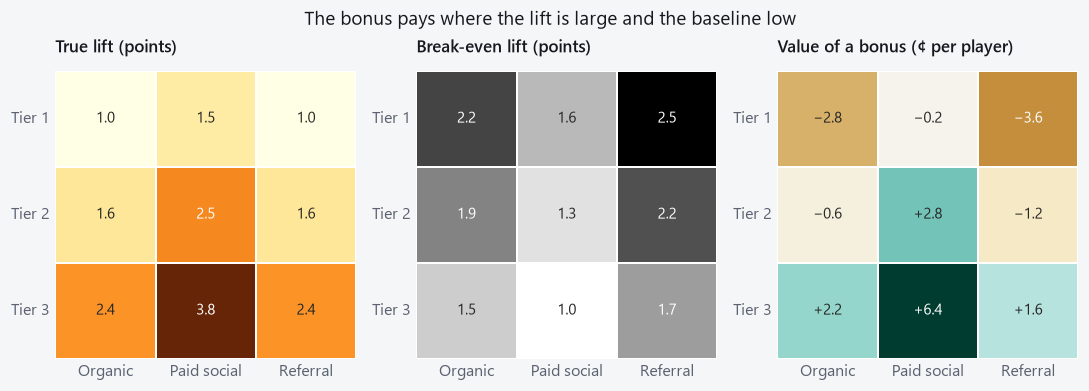

In [16]:
# Where the bonus pays, in truth
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
grid = lambda col: truth[col].to_numpy().reshape(len(TIERS), len(CHANNELS))
for ax, (col, title, fmt, cmap, scale) in zip(axes, [
        ("true_lift", "True lift (points)", ".1f", "YlOrBr", 100),
        ("break_even", "Break-even lift (points)", ".1f", "Greys", 100),
        ("value_cents", "Value of a bonus (¢ per player)", "+.1f", "BrBG", 1)]):
    vals = grid(col) * scale
    labels = np.vectorize(lambda v: format(v, fmt).replace("-", "−"))(vals)
    sns.heatmap(vals, ax=ax, annot=labels, fmt="", cbar=False, cmap=cmap, linewidths=1, linecolor="white",
                center=0 if col == "value_cents" else None, xticklabels=CHANNELS, yticklabels=TIERS,
                annot_kws={"fontsize": 10})
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("")
    ax.tick_params(axis="y", rotation=0)
fig.suptitle("The bonus pays where the lift is large and the baseline low", y=1.04)
savefig(fig, "08_truth_by_cell")

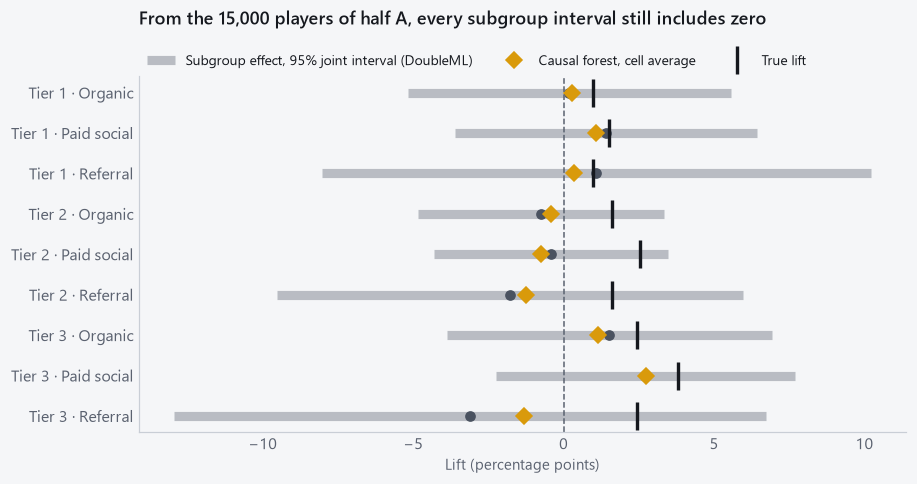

In [17]:
# Estimated vs true effect by cell
cells = list(truth.index)
fcell = pd.Series(tau_hat[B]).groupby(np.asarray(exp_cell)[B]).mean().reindex(cells)
fig, ax = plt.subplots(figsize=(9, 4.2))
ypos = np.arange(len(cells))[::-1]
ax.hlines(ypos, gates.lo.reindex(cells) * 100, gates.hi.reindex(cells) * 100, color=CONTROL, lw=6, alpha=0.35,
          label="Subgroup effect, 95% joint interval (DoubleML)")
ax.plot(gates.gate.reindex(cells) * 100, ypos, "o", color=CONTROL, ms=6)
ax.plot(fcell * 100, ypos, "D", color=TREAT, ms=7, label="Causal forest, cell average")
ax.plot(truth.true_lift * 100, ypos, "|", color=INK, ms=18, mew=2.2, label="True lift")
ax.axvline(0, color=MUTED, ls="--", lw=1)
ax.set_yticks(ypos, cells)
ax.set_xlabel("Lift (percentage points)")
ax.set_title("From the 15,000 players of half A, every subgroup interval still includes zero", pad=34)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=3, borderaxespad=0.2, fontsize=9)
ax.grid(axis="y", visible=False)
savefig(fig, "08_estimates_vs_truth")

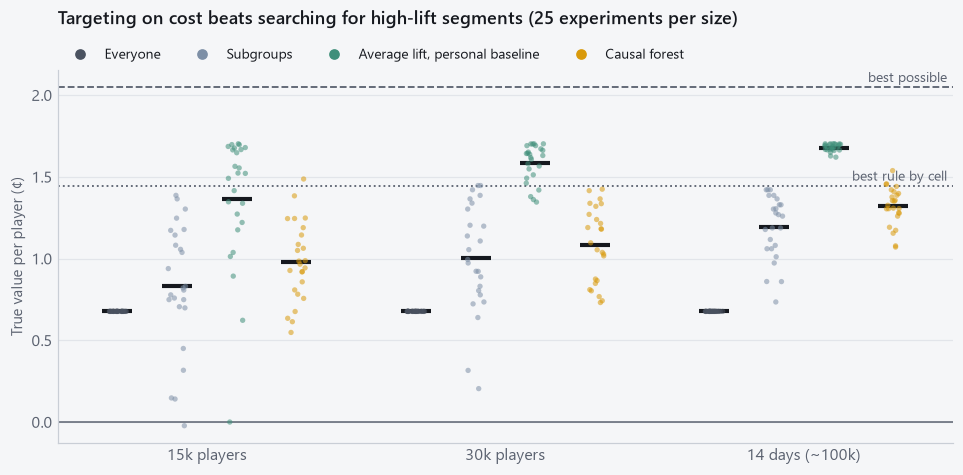

In [18]:
# Value of each rule, repeated experiments
RULE_COLS = {"true_all": "Everyone", "true_subgroups": "Subgroups", "true_baseline_rule": "Average lift, personal baseline",
             "true_forest": "Causal forest"}
PAL = {"Everyone": CONTROL, "Subgroups": "#7d8fa6", "Average lift, personal baseline": "#3f8f7a", "Causal forest": TREAT}
long = rep.melt(id_vars="n", value_vars=list(RULE_COLS), var_name="rule", value_name="value")
long["rule"] = long.rule.map(RULE_COLS)
long["size"] = long.n.map(lambda n: f"{n // 1000}k players" if n < 100_000 else "14 days (~100k)")
fig, ax = plt.subplots(figsize=(10.5, 4.4))
sns.stripplot(data=long, x="size", y="value", hue="rule", dodge=True, ax=ax, size=3.5, alpha=0.55, jitter=0.12,
              palette=PAL, legend=False)
sns.pointplot(data=long, x="size", y="value", hue="rule", dodge=0.6, ax=ax, linestyle="none", errorbar=None,
              markers="_", markersize=20, palette={k: INK for k in PAL}, legend=False)
for yv, label, ls in [(true_value(np.isin(pop_cell, treat_cells_true)), "best rule by cell", ":"),
                      (true_value(TRUE_G > 0), "best possible", "--")]:
    ax.axhline(yv, color=MUTED, ls=ls, lw=1.2)
    ax.text(2.48, yv + 0.03, label, color=MUTED, fontsize=9, ha="right")
ax.axhline(0, color=MUTED, lw=1)
ax.set_xlabel("")
ax.set_ylabel("True value per player (¢)")
ax.set_title(f"Targeting on cost beats searching for high-lift segments ({REPS} experiments per size)", pad=30)
handles = [plt.Line2D([], [], marker="o", ls="none", color=c, label=k) for k, c in PAL.items()]
ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.0), ncols=4, borderaxespad=0.2, fontsize=9)
ax.grid(axis="x", visible=False)
savefig(fig, "08_value_by_rule")

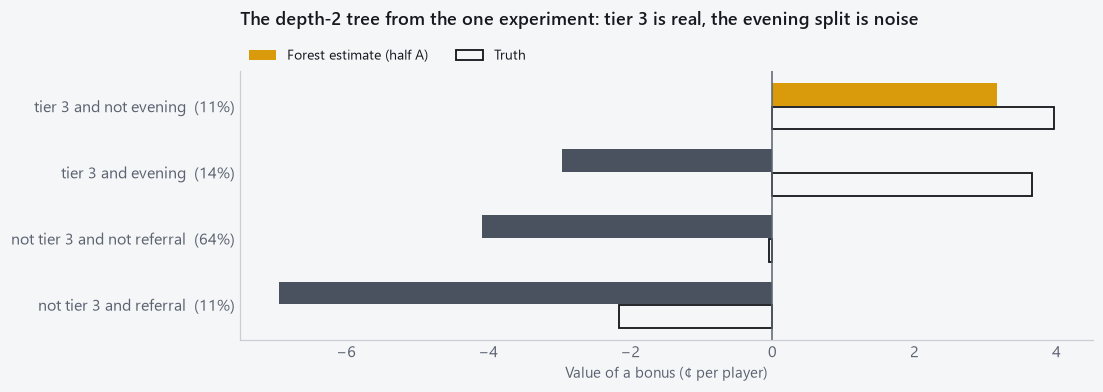

In [19]:
# Shallow tree
fig, ax = plt.subplots(figsize=(10, 0.7 + 0.62 * len(leaves)))
yl = np.arange(len(leaves))[::-1]
est, tru = leaves["forest: value of a bonus (¢/player)"], leaves["true value of a bonus (¢/player)"]
ax.barh(yl + 0.18, est, height=0.34, color=[TREAT if b else CONTROL for b in leaves.bonus], label="Forest estimate (half A)")
ax.barh(yl - 0.18, tru, height=0.34, color="none", edgecolor=INK, lw=1.2, label="Truth")
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(yl, [f"{r.replace('_', ' ')}  ({s:.0%})" for r, s in zip(leaves.rule, leaves["share of players"])])
ax.set_xlabel("Value of a bonus (¢ per player)")
ax.set_title("The depth-2 tree from the one experiment: tier 3 is real, the evening split is noise", pad=30)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, borderaxespad=0.2, fontsize=9)
ax.grid(axis="y", visible=False)
savefig(fig, "08_policy_tree")

## 8. Results

In [20]:
s30 = summary.loc[N_FINAL]
print(f"One experiment, 30,000 players: pre-specified test p = {wald.pvalue:.3f}; forest calibration p = {blp.pvals[0]:.3f}")
print(f"True value per player: everyone {scores.loc['Everyone', 'true value (¢/player)']:.2f}¢, "
      f"subgroups {scores.loc['Subgroups (tier × channel)', 'true value (¢/player)']:.2f}¢, "
      f"forest {scores.loc['Causal forest', 'true value (¢/player)']:.2f}¢, tree {true_value(tree_rule):.2f}¢, "
      f"best possible {true_value(TRUE_G > 0):.2f}¢")
print("Repeated experiments (mean true value, ¢ per player):")
print(summary[["treat_all", "subgroups", "baseline_rule", "forest", "forest_beats_subgroups", "forest_beats_baseline_rule",
               "heterogeneity_found_ols", "heterogeneity_found_forest", "blp_slope"]].round(3).to_string())

One experiment, 30,000 players: pre-specified test p = 0.076; forest calibration p = 0.785
True value per player: everyone 0.68¢, subgroups 0.89¢, forest 0.63¢, tree 0.45¢, best possible 2.05¢
Repeated experiments (mean true value, ¢ per player):
        treat_all  subgroups  baseline_rule  forest  forest_beats_subgroups  forest_beats_baseline_rule  heterogeneity_found_ols  heterogeneity_found_forest  blp_slope
n                                                                                                                                                                      
15000       0.677      0.834          1.364   0.979                    0.76                         0.2                     0.20                        0.08      0.072
30000       0.677      1.006          1.585   1.086                    0.48                         0.0                     0.28                        0.08      0.093
100000      0.677      1.191          1.679   1.319                    0.60      

- **Targeting pays.** In truth the bonus pays in 4 of the 9 tier × channel cells (43% of players). Giving it to everyone earns 0.68¢ per player; the best rule by cell earns 1.45¢; the best possible rule, knowing each player's true lift and baseline, 2.05¢.
- **Most of the gain is on the cost side, and it needs no search for segments.** "Average lift, personal baseline" (the average lift the test already measured, and the CUPAC score as each player's baseline) earns 1.36¢ at 15,000 players, 1.58¢ at 30,000 and 1.68¢ over 14 days, above the best rule by cell from 30,000 players on. It never did worse than treating everyone at 30,000 players or more (2 of 25 runs at 15,000, when the average lift was badly underestimated).
- **The causal forest finds little real heterogeneity at these sizes.** Its calibration slope on the held-out half averages 0.07–0.13 (1 would mean its ranking is fully right), and the test detects heterogeneity in only 8%, 8% and 20% of runs. Its rule (0.98¢, 1.09¢, 1.32¢) does beat the subgroup rule (0.83¢, 1.01¢, 1.19¢) more often than not, but it never beat the cost-side rule at 30,000 players or more. Most of what it gains comes from the baseline term it shares with that rule.
- **The safeguards do their job: they say "not enough evidence" most of the time.** The pre-specified interaction test finds heterogeneity in 20%, 28% and 64% of runs. Under the brief's rule (no segments shown before an overall test passes), the page would show no segment list for a typical 30,000-player run. The lift really does vary (tier 3 gets 1.5×), but one experiment of this size cannot show it reliably.
- **The held-out estimate of the gain is honest on average but noisy.** At 30,000 players the forest's gain over treating everyone is estimated on half B at +0.50¢ on average against a true +0.41¢, but a single estimate is off by about ±0.8¢, as much as the gain itself.
- **The one experiment above is an unlucky draw**, which is why section 6 exists. Its half A put the average lift at +0.5 points (truth +2), so every rule fitted on it treats too few players, and the forest and the cost-side rule (0.63¢ each) both fall just short of treating everyone (0.68¢). The depth-2 tree splits on tier 3, which is real, and then on evening sign-ups, which is noise.
- **The assumption behind the cost-side rule holds here.** In the experiment the lift *grows* as the predicted baseline falls (−0.55 points per +10 points of baseline, interval −1.20 to +0.10), because in this world tier 3 has both the lowest baseline and the largest lift. In a real game the lift could instead be concentrated among engaged players with a high baseline; that interaction is the check to run before using the rule.

**For the page.** The honest headline is that the targeting question is answered mostly by the economics, not by a forest: give the bonus to the players least likely to reach level 5 anyway, unless the experiment shows the lift shrinks for them. The causal forest is worth showing as the method the brief asks for, with its tests failing as often as they do. Daniel to decide what the "Ship it to whom?" section shows.

## 9. What gets promoted

Nothing runs in the browser: the brief rules out refitting forests on the page. The page's "Ship it to whom?" section (After tab) shows the repeated experiments and the truth by cell, precomputed, with the safeguards stated.

| Item | Goes to | Guarded by |
|---|---|---|
| Value of a bonus per player, $G = (V - c)\tau - c\,p_0$ | already `ablab.guardrail.value_from_lift` | parity cell below |
| Targeting results (truth by cell, rule values by size, tests) | `scripts/targeting_page.py` → `web/public/targeting.json` → `TargetingSection.svelte` | `tests/test_targeting_page.py`; parity cell below |

## 10. Production parity

The value of a bonus used for targeting is the guardrail's function from notebook 06, applied player by player.

In [21]:
tau_i, p0_i = pop.tau.to_numpy(), pop.p0.to_numpy()
assert np.allclose(TRUE_G, (V - COST) * tau_i - COST * p0_i)
assert np.allclose(truth.break_even, (COST * pop.p0 / (V - COST)).groupby(pop_cell, observed=True).mean())
assert abs(guardrail.value_from_lift(0.0, CFG["experiment"]["baseline_rate"], PLAN)
           + COST * CFG["experiment"]["baseline_rate"]) < 1e-15
print("targeting uses ablab.guardrail.value_from_lift: same economics as the page's 'Pays for itself'")

page = json.loads(Path("../web/public/targeting.json").read_text())       # scripts/targeting_page.py
page_cells = pd.DataFrame(page["truth"]["cells"]).set_index(["tier", "channel"])
for cell_name, row in truth.iterrows():
    tier_name, channel_name = cell_name.split(" · ")
    assert abs(page_cells.loc[(tier_name, channel_name), "value_cents"] - row.value_cents) < 1e-9
assert abs(page["truth"]["best_possible_cents"] - true_value(TRUE_G > 0)) < 1e-9
assert abs(page["truth"]["best_by_cell_cents"] - true_value(np.isin(pop_cell, treat_cells_true))) < 1e-9
print("web/public/targeting.json reproduces this notebook's truth and repeated experiments")

targeting uses ablab.guardrail.value_from_lift: same economics as the page's 'Pays for itself'
web/public/targeting.json reproduces this notebook's truth and repeated experiments


## Further reading

Heterogeneous effects, causal forests, and choosing who gets a treatment. Where to find them: **[local]** = `docs/papers/` in this project (kept out of the repo) · **[Vega: folder]** = `Vega/paper-library/pdfs/<folder>/` (Vega's library also has text versions in `paper-library/md/` and notes in `paper-library/papers/`) · **[airline library: folder]** = `Projects/airline-experimentation/paper-library/pdfs/<folder>/` (a copy of Vega's library plus airline-related extras) · **[online]** = not in any library yet. ★ = read first.

Theory notes in this project: [hte](../docs/theory/hte.md), [causal-forests](../docs/theory/causal-forests.md), [policy-learning](../docs/theory/policy-learning.md), [metalearners](../docs/theory/metalearners.md), [dml](../docs/theory/dml.md).

- ★ Wager, S. (2025). *Causal Inference: A Statistical Learning Approach* (book draft, Nov 2025), chapters 4 (heterogeneous effects) and 5 (policy learning). The notation used here. **[Vega: 00-foundational]**
- ★ Wager, S., & Athey, S. (2018). Estimation and inference of heterogeneous treatment effects using random forests. *JASA* 113(523). Causal forests and honest trees. **[online]** https://doi.org/10.1080/01621459.2017.1319839
- ★ Athey, S., Tibshirani, J., & Wager, S. (2019). Generalized random forests. *Annals of Statistics* 47(2). The forest econml implements. **[Vega: 11-hte-metalearners-forests]**
- Nie, X., & Wager, S. (2021). Quasi-oracle estimation of heterogeneous treatment effects. *Biometrika* 108(2). The R-learner. **[online]** https://doi.org/10.1093/biomet/asaa076
- Künzel, S. R., Sekhon, J. S., Bickel, P. J., & Yu, B. (2019). Metalearners for estimating heterogeneous treatment effects using machine learning. *PNAS* 116(10). S-, T- and X-learners, for comparison. **[Vega: 11-hte-metalearners-forests]**
- Chernozhukov, V., Chetverikov, D., Demirer, M., Duflo, E., Hansen, C., Newey, W., & Robins, J. (2018). Double/debiased machine learning for treatment and structural parameters. *The Econometrics Journal* 21(1). Cross-fitting and orthogonal scores. **[Vega: 01-causal-ml-dml]**
- Ahrens, A., Chernozhukov, V., Hansen, C., Kozbur, D., Schaffer, M., & Wiemann, T. (2025). An introduction to double/debiased machine learning. arXiv:2504.08324. The gentle version of the above. **[Vega: 01-causal-ml-dml]**
- Chernozhukov, V., Demirer, M., Duflo, E., & Fernández-Val, I. (2018). Generic machine learning inference on heterogeneous treatment effects in randomized experiments. NBER WP 24678. The calibration (BLP) test. **[online]** https://doi.org/10.3386/w24678
- Yadlowsky, S., Fleming, S., Shah, N., Brunskill, E., & Wager, S. (2025). Evaluating treatment prioritization rules via rank-weighted average treatment effects. *JASA*. The targeting (TOC) curve. **[online]** https://arxiv.org/abs/2111.07966
- Athey, S., & Wager, S. (2021). Policy learning with observational data. *Econometrica* 89(1). Learning who to treat. **[online]** https://doi.org/10.3982/ECTA15732
- Kitagawa, T., & Tetenov, A. (2018). Who should be treated? Empirical welfare maximization methods for treatment choice. *Econometrica* 86(2). **[online]** https://doi.org/10.3982/ECTA13288
- Chernozhukov, V., Hansen, C., Kallus, N., Spindler, M., & Syrgkanis, V. (2024). *Applied Causal Inference Powered by ML and AI*. The applied book, with code. **[Vega: 00-foundational]**
- Spotify Engineering. *Experimenting with Machine Learning to Target In-App Messaging* (blog). Targeting in an industry setting. **[Vega: 08-personalization-and-platform-craft]**
- grf guide (grf-labs.github.io/grf). The practical causal-forest guide: doubly robust scores, BLP, RATE. **[online]** https://grf-labs.github.io/grf/articles/grf_guide.html